<h1>Практическая работа: "Бинарная логистическая регрессия"</h1>

__Задача бинарной классификации__

___Некая фирма провела анализ зависимости расхода денежных средств на рекламу и эффекта от нее. Если эффект присутствовал, 
то в датасете ставилась 1, в противном случае - 0. Результаты были представоены в виде двух DataFrame х и y.<br>
Произыести бинарную классификацию с использованием логистической регрессии.___  

In [2]:
# NumPy для формул, pandas для таблицы, matplotlib для графиков.
#Загрузим необходимые библиотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# x — расход на рекламу, Y — был ли эффект: 1 или 0.
#Исходные данные: x - расходы на рекламу, Y - объемы продаж
x = pd.DataFrame(np.array([39, 36, 60, 21, 27, 12, 51, 57, 54, 42, 18, 9, 48, 66, 6, 30, 24, 33, 15, 21, 100, 200]))
Y = pd.DataFrame(np.array([1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1]))
#display(x, Y)

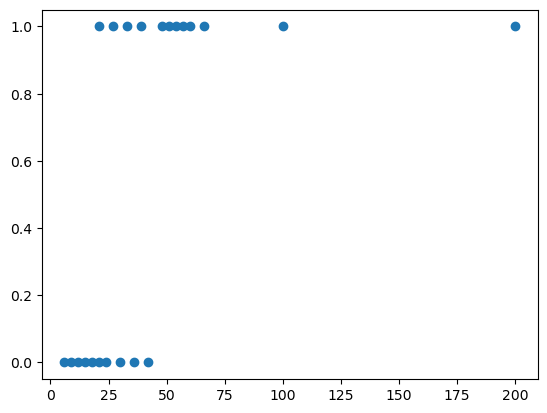

In [4]:
# Каждая точка — одна кампания. Линейной границы между 0 и 1 не видно.
plt.scatter(x,Y)

_Попробуем разделить эти точки прямой линией, отделяющей один класс от другого. 
Модель начинает плохо работать в случае добавления новых точек на больших значениях x:_

In [5]:
# Прямая МНК. Для меток 0 и 1 она не обязана оставаться внутри отрезка [0, 1].
a1 = ((x-x.mean())*(Y-Y.mean())).mean()/((x-x.mean())**2).mean()
a0 = Y.mean() - a1*x.mean()
print("Y = ", a0, " + ", a1, " * x")
x_space = np.linspace(6,70,20)
Y_pred = a0.item() + a1.item()*x_space

Y =  0    0.266493
dtype: float64  +  0    0.006333
dtype: float64  * x


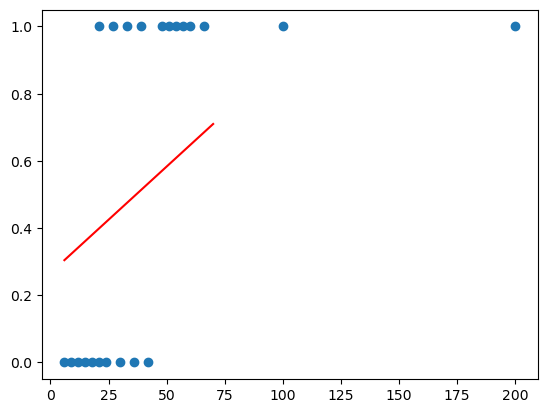

In [6]:
# Красная прямая поверх точек. На больших x она уходит выше 1.
plt.plot(x_space, Y_pred, 'r')
plt.scatter(x, Y)

<h2>Функция логистической регрессии</h2>

__Сигмоида__

Возможное решение упомянутых выше сложностей — пропустить значение линейной регрессии через сигмоиду (sigmoid function), 
которая при любом значении x не выйдет из необходимого нам диапазона от 0 до 1. <br>
<h3>$g(x) = \frac{1}{1+ e^{-x}}$</h3>

 <img src='images/ris1.png' width=320, heigth=240>

<h3>Logistic loss или функция кросс-энтропии</h3>

В модели логистической регрессии мы не можем использовать MSE. Дело в том, 
что если мы поместим результат сигмоиды (представляющей собою нелинейную функцию) в MSE, 
то на выходе получим невыпуклую функцию (non-convex), глобальный минимум которой довольно сложно найти.
 <img src='images/ris2.png' width=520, heigth=240>
    Вместо MSE мы будем использовать функцию логистической ошибки, которую еще называют функцией бинарной кросс-энтропии (log loss, binary cross-entropy loss).

__График и формула функции логистической ошибки__<br>
 <img src='images/ris3.png' width=420, heigth=240>

$J(\theta)=-\frac{1}{n} \sum{y*log(h_{\theta}(x))+(1-y)*log(1-h_{\theta}(x))}$

<h3>Оценка качества модели</h3>

__Матрицa ошибок (confusion matrix)__<br>
 <img src='images/ris4.png' width=420, heigth=240><br>
Доля правильно предсказанных значений называется accuracy. Чтобы ее посчитать, мы берем те значения,
    которые предсказаны верно (TP + TN) и делим на общее количество прогнозов.<br>
    <h3>$accuracy=\frac{TP+TN}{TP+TN+FP+FN}$</h3>

<h2>Конкретизация задачи:</h2>

Реализовать класс модели логистической регрессии с использованием:

а) максимизации логарифмического правдоподобия методом градиентного подъема

б) минимизации функции потерь (кросс-энтропии) методом градиентного спуска

Сравнить результаты (время исполнения и достигнутые значения accuracy и f1) в случаях а и б при одном и том же числе шагов и скорости обучения.

In [7]:
# Два способа в одном классе.
# LL — максимум логарифма правдоподобия, к коэффициентам прибавляем градиент.
# CE — минимум кросс-энтропии, градиент вычитаем.
# Кросс-энтропия равна минус правдоподобию, поэтому сами шаги совпадают.
class LogisticRegressionGD(object):
    def __init__(self):
        # Заготовка на два коэффициента. Настоящую длину задаёт fit по ширине X.
        self.a = np.zeros(2).reshape(1, 2)

    def sigmoid(self, x):
        # Сигмоида переводит логит X @ a в вероятность класса 1.
        return 1 / (1 + np.exp(-x @ self.a))

    def predict(self, x):
        # Здесь возвращаются вероятности. Порог 0.5 применяется в accuracy.
        return self.sigmoid(x)

    def coefs(self):
        return self.a

    def LogLikelihood(self, x, Y):
        # Суммарный логарифм правдоподобия. Эту величину максимизируем.
        return (Y * np.log(self.predict(x)) + (1 - Y) * np.log(1 - self.predict(x))).sum()

    def CrossEntropy(self, x, Y):
        # Кросс-энтропия — та же сумма с обратным знаком. Её минимизируем.
        return (-Y * np.log(self.predict(x)) - (1 - Y) * np.log(1 - self.predict(x))).sum()

    def accuracy(self, x, Y):
        # Доля верных ответов при пороге 0.5.
        return ((self.predict(x) > 0.5) == Y).mean()

    def fit(self, x, Y, alpha=0.01, epsylon=0.01, max_steps=10000, Rtype="LL"):
        # По одному коэффициенту на каждый столбец, включая свободный член.
        self.a = np.zeros(x.shape[1]).reshape(x.shape[1], 1)
        steps, errors = [], []
        step = 0
        for _ in range(max_steps):
            if Rtype == "LL":
                new_error = self.LogLikelihood(x, Y)
                # Градиент правдоподобия: X^T (y - p) / n. Подъём прибавляет его.
                dT_a = x.T @ (Y - self.predict(x)) / x.shape[0]
                self.a += alpha * dT_a
            elif Rtype == "CE":
                new_error = self.CrossEntropy(x, Y)
                # Градиент кросс-энтропии противоположен градиенту правдоподобия.
                dT_a = -x.T @ (Y - self.predict(x)) / x.shape[0]
                # Спуск вычитает градиент функции потерь.
                self.a -= alpha * dT_a
            step += 1
            steps.append(step)
            errors.append(new_error)
            # Останов по epsylon выключен: оба способа должны сделать одно и то же число шагов.
        return steps, errors


In [8]:
# Столбец единиц — свободный член. Без него прямая обязана проходить через начало координат.
x_ = x.copy()

import time

intercept = np.ones((x.shape[0], 1))
x_ = pd.DataFrame(np.concatenate((intercept, x), axis = 1))

In [9]:
# Оба способа запускаем с одним шагом и одним числом итераций, иначе сравнение нечестное.
start_time_CE = time.time()
regr_CE = LogisticRegressionGD()
steps_CE, errors_CE =  regr_CE.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "CE") 

display(f"Время обучения: {time.time() - start_time_CE} сек.")

start_time_LL = time.time()
regr_LL = LogisticRegressionGD()
steps_LL, errors_LL =  regr_LL.fit(x_, Y, alpha = 0.01, epsylon = 0.01, max_steps = 10000, Rtype = "LL") 

display(f"Время обучения: {time.time() - start_time_LL} сек.")

'Время обучения: 9.622706890106201 сек.'

'Время обучения: 9.637336730957031 сек.'

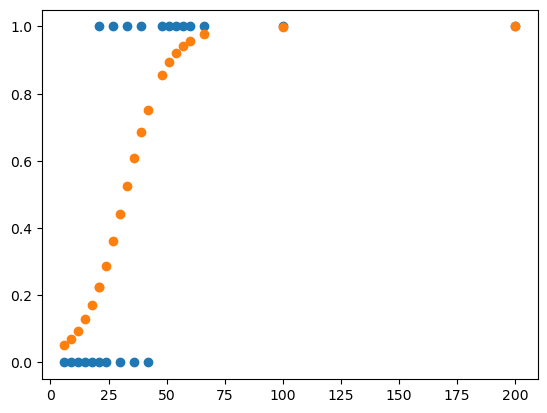

In [10]:
# Синие точки — истинные метки, оранжевые — вероятности способа CE.
Y_Pred = regr_CE.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [11]:
# Коэффициенты CE: первая строка — свободный член, вторая — вес расхода на рекламу.
display(regr_CE.coefs())
#display(x_)

,0
0,-3.598724
1,0.112149


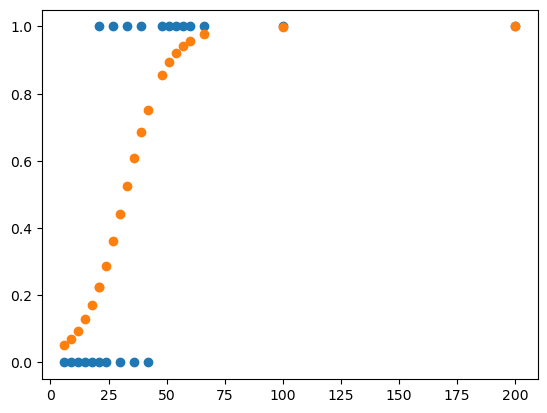

In [12]:
# Те же вероятности для максимизации правдоподобия.
Y_Pred = regr_LL.predict(x_)
plt.scatter(x, Y)
plt.scatter(x, Y_Pred)

In [13]:
# Коэффициенты LL. После одинакового числа шагов они совпадают с коэффициентами CE.
display(regr_LL.coefs())
#display(x_)

,0
0,-3.598724
1,0.112149


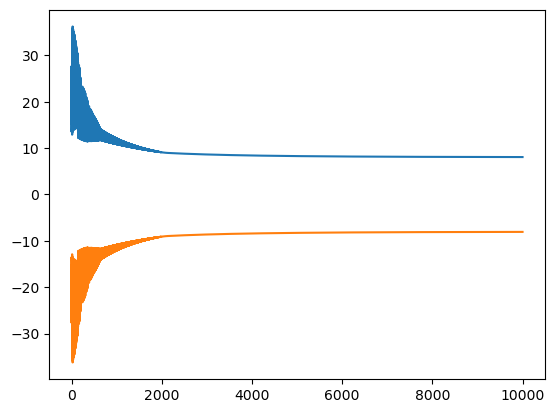

In [14]:
# История цели. Кросс-энтропия убывает, логарифм правдоподобия возрастает, кривые зеркальны.
plt.plot(steps_CE, errors_CE)
plt.plot(steps_LL, errors_LL)

In [15]:
# Accuracy при пороге 0.5 на тех же 22 кампаниях, на которых учились.
print(regr_CE.accuracy(x_, Y))
print(regr_LL.accuracy(x_, Y))

0    0.818182
dtype: float64
0    0.818182
dtype: float64


Реализовать расчеты способами а и б для набора данных из файла insclass_train.csv/
Для 151 406 договоров страхования транспортных средств известны значения ряда признаков, в том числе пол, возраст, стаж вождения и коэффициент бонус-малус водителя, тип, марка, модель, год выпуска, страна – производитель, мощность и объем двигателя, а также признак target, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае (файл insclass_train.csv).

Требуется построить модель, предсказывающую значение признака target для 22 624 договоров из тестового набора данных (файл insclass_test.csv).

В обучающем наборе данных для каждого договора известны следующие поля:

variable_1 - агрегированный коэффициент бонус-малус (повышающий или понижающий стоимость полиса в зависимости от аварийности в предыдущие периоды);

variable_2 - индикатор расторжения договора по инициативе страхователя (клиента);

variable_3 - индикатор расторжения договора по инициативе страховщика (страховой компании);

variable_4 - идентификатор года выпуска транспортного средства;

variable_5 - идентификатор страны - производителя транспортного средства;

variable_6 - мощность двигателя в лошадиных силах;

variable_7 - объем двигателя в куб. см;

variable_8 - идентификатор стороны расположения руля (левый или правый);

variable_9 - пробег транспортного средства, покрываемый гарантией производителя;

variable_10 - индикатор действия гарантии на транспортное средство;

variable_11 - "мультидрайв" - индикатор допуска к управлению транспортным средством более одного водителя;

variable_12 - возраст транспортного средства (в мес.);

variable_13 - возраст водителя с максимальным стажем;

variable_14 - коэффициент возраст-стаж;

variable_15 - коэффициент краткосрочности;

variable_16 - коэффициент мощности;

variable_17 - коэффициент "мультидрайв";

variable_18 - территориальный коэффициент;

variable_19 - коэффициент "КНДР";

variable_20 - идентификатор канала продаж;

variable_21 - марка транспортного средства;

variable_22 - модель транспортного средства;

variable_23 - индикатор отечественных транспортных средств;

variable_24 - пол водителя с максимальным коэффициентом "возраст-стаж";

variable_25 - индикатор пролонгации;

variable_26 - индикатор совпадения собственника транспортного средства и водителя;

variable_27 - стаж водителя с максимальным коэффициентом "возраст-стаж";

variable_28 - тип транспортного средства;

target - класс риска, равный 1, если заключение договора с клиентом является рисковым, и 0 в противном случае.

---

# Индивидуальное задание. Страховые договоры, два способа обучения логистической регрессии

Нужно теми же двумя способами, что и на учебном примере с рекламой, предсказать признак `target` по файлу `insclass_train.csv`:

- **(а)** максимизировать логарифм правдоподобия градиентным подъёмом;
- **(б)** минимизировать кросс-энтропию градиентным спуском.

Сравниваем время, accuracy и F1 при одном и том же шаге обучения и одном и том же числе итераций. Дополнительно считаем precision и recall: F1 является их средним гармоническим, и без них непонятно, за счёт чего получилась цифра.

В условии упомянут файл `insclass_test.csv` на 22 624 договора. Берём 15% под итоговую проверку, ещё 15% оставляем, чтобы выбрать порог вероятности. В обучение модели эти две части не входят.

Учебный класс на `DataFrame` для такого объёма не подходит: на 22 строках 10 000 шагов уже занимают несколько секунд, на 150 тысячах строк счёт шёл бы часами. Ниже те же формулы, но матрицы считаются в `numpy`.


In [16]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

%matplotlib inline
plt.rcParams['font.family'] = 'DejaVu Sans'
pd.set_option('display.float_format', lambda value: f'{value:0.4f}')
pd.set_option('display.max_columns', 40)


In [17]:
data_path = Path('insclass_train.csv')
if not data_path.exists():
    raise FileNotFoundError('Рядом с тетрадью нет insclass_train.csv')

contracts = pd.read_csv(data_path)
print('Файл:', data_path.resolve())
print('Размер:', contracts.shape)
print('Договоров с target = 1 (рисковый):', int((contracts['target'] == 1).sum()))
print('Договоров с target = 0:', int((contracts['target'] == 0).sum()))
print(f"Доля рисковых: {contracts['target'].mean():.4f}")

# Доля пропусков по столбцам, где пропуск вообще есть.
missing_rate = contracts.isna().mean().sort_values(ascending=False)
missing_rate = missing_rate[missing_rate > 0]
display((missing_rate * 100).rename('пропуски, %').to_frame())
display(contracts.head(3))


Файл: /mnt/ПРОЕКТЫ/ПАРЫ/Машинное_обучение/Текущий контроль_4/insclass_train.csv
Размер: (151406, 29)
Договоров с target = 1 (рисковый): 14459
Договоров с target = 0: 136947
Доля рисковых: 0.0955


,"пропуски, %"
variable_15,99.9914
variable_9,88.7917
variable_7,63.1672
variable_8,19.7476
variable_14,1.9332
variable_24,1.4577
variable_27,1.3652
variable_13,1.0944
variable_12,1.0092
variable_6,0.0733


,variable_1,variable_2,variable_3,variable_4,variable_5,variable_6,variable_7,variable_8,variable_9,variable_10,variable_11,variable_12,variable_13,variable_14,variable_15,variable_16,variable_17,variable_18,variable_19,variable_20,variable_21,variable_22,variable_23,variable_24,variable_25,variable_26,variable_27,variable_28,target
0,w200,0,0,14,q2,98.0000,NaN,0.0000,NaN,0,0,166.2670,49.0417,80.9852,NaN,98.6481,80.9852,80.9852,127.1132,C,j2,h45,0,0.0000,0,1,19.3235,t1,0
1,w160,0,0,7,q11,106.0000,NaN,0.0000,NaN,0,0,80.3386,82.7569,80.9852,NaN,118.1166,80.9852,38.7043,148.9057,C,j33,h234,0,1.0000,0,1,41.1779,t1,0
2,w200,0,0,4,q3,123.0000,NaN,0.0000,NaN,0,0,38.5199,35.8423,80.9852,NaN,162.5140,80.9852,273.4134,154.2449,B,j12,h28,0,0.0000,0,1,3.6144,t1,0


## Подготовка признаков

Градиентный шаг из учебного примера рассчитан на числа сравнимого масштаба и на матрицу умеренной ширины. Сырой файл этому не соответствует, поэтому перед обучением делаем следующее.

- `variable_3` везде равна 0. Такой столбец не меняет логит.
- `variable_9` пуст почти у всех и содержит значения порядка 10^36. Это испорченный столбец, а не пробег.
- `variable_15` пуст почти в каждой строке.
- `variable_7` (объём двигателя) пуст у 63% договоров. Мощность уже есть в `variable_6`, дублировать её полупустым столбцом не будем.
- Короткие категориальные коды переводим в индикаторы 0/1. Один уровень каждого признака выбрасываем, иначе индикаторы вместе со свободным членом линейно зависимы и шаг по этой комбинации не имеет единственного решения.
- Марка (`variable_21`, 192 уровня) и модель (`variable_22`, 1475 уровней) в индикаторы не разворачиваем: матрица стала бы слишком широкой для честного полного градиента на 10 000 шагов. Вместо этого подставляем частоту уровня на обучении.
- Пропуск, которого больше 1%, сам может быть связан с риском. До заполнения заводим столбец «значение отсутствовало». Числа потом заполняем медианой обучения, коды — модой обучения. Статистики теста не используем.
- После кодирования вычитаем среднее и делим на разброс по обучению. Столбец единиц для свободного члена добавляем уже после этого, чтобы он остался единицами.

Все правила частот, мод, медиан и масштаба считаем только по обучающим 70%.


In [18]:
# Почему столбец удалён — попадёт в таблицу ниже, это часть отчёта, а не скрытый фильтр.
drop_reasons = pd.DataFrame(
    [
        ('variable_3', 'константа 0, на логит не влияет'),
        ('variable_7', 'объём двигателя пуст у 63% строк и дублирует мощность variable_6'),
        ('variable_9', 'почти везде пусто и есть значения вплоть до 1e36'),
        ('variable_15', 'коэффициент краткосрочности пуст почти у всех договоров'),
    ],
    columns=['столбец', 'почему убрали'],
)
display(drop_reasons)

feature_frame = contracts.drop(columns=list(drop_reasons['столбец']))
y_all = feature_frame['target'].to_numpy()
X_all = feature_frame.drop(columns='target')

# Сначала отрезаем 30%, затем делим их пополам: 15% на порог и 15% на итог.
# stratify держит долю рисковых договоров одинаковой во всех трёх частях.
X_train_raw, X_holdout, y_train, y_holdout = train_test_split(
    X_all, y_all, test_size=0.30, random_state=42, stratify=y_all,
)
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, random_state=42, stratify=y_holdout,
)

print('Обучение:', len(y_train), f', доля рисковых {y_train.mean():.4f}')
print('Валидация для порога:', len(y_val), f', доля рисковых {y_val.mean():.4f}')
print('Тест:', len(y_test), f', доля рисковых {y_test.mean():.4f}')

# Короткие коды — в индикаторы. Марка и модель — в частоту.
CAT_LOW = ['variable_1', 'variable_5', 'variable_20', 'variable_28']
CAT_HIGH = ['variable_21', 'variable_22']
NUMERIC = X_train_raw.select_dtypes(include='number').columns.tolist()


def prepare_features(train_frame, other_frames):
    """Кодирует признаки. Все статистики берутся из train_frame."""
    train_frame = train_frame.copy()
    others = [frame.copy() for frame in other_frames]

    # Индикатор пропуска ставим до заполнения, иначе информация о дырке пропадёт.
    missed = [column for column in train_frame.columns if train_frame[column].isna().mean() > 0.01]
    print('Столбцы с индикатором пропуска:', missed)
    for column in missed:
        flag = column + '_nan'
        train_frame[flag] = train_frame[column].isna().astype(np.float64)
        for frame in others:
            frame[flag] = frame[column].isna().astype(np.float64)

    for column in NUMERIC:
        median = train_frame[column].median()
        train_frame[column] = train_frame[column].fillna(median)
        for frame in others:
            frame[column] = frame[column].fillna(median)

    for column in CAT_LOW + CAT_HIGH:
        mode = train_frame[column].mode(dropna=True).iloc[0]
        train_frame[column] = train_frame[column].fillna(mode)
        for frame in others:
            frame[column] = frame[column].fillna(mode)

    for column in CAT_HIGH:
        # Частота уровня на обучении. Невстреченный на тесте код получает 0.
        frequency = train_frame[column].value_counts(normalize=True)
        train_frame[column] = train_frame[column].map(frequency).astype(float)
        for frame in others:
            frame[column] = frame[column].map(frequency).fillna(0.0).astype(float)

    # drop_first убирает базовый уровень, чтобы не было линейной зависимости со свободным членом.
    train_frame = pd.get_dummies(train_frame, columns=CAT_LOW, drop_first=True)
    prepared_others = []
    for frame in others:
        frame = pd.get_dummies(frame, columns=CAT_LOW, drop_first=True)
        # Столбцы теста выравниваем по обучению. Нового уровня в тесте в матрице не появится.
        frame = frame.reindex(columns=train_frame.columns, fill_value=0)
        prepared_others.append(frame.astype(np.float64))

    return train_frame.astype(np.float64), prepared_others


X_train_df, (X_val_df, X_test_df) = prepare_features(X_train_raw, [X_val_raw, X_test_raw])
print('Число столбцов после кодирования:', X_train_df.shape[1])
print('Пропусков после подготовки:', int(X_train_df.isna().sum().sum() + X_val_df.isna().sum().sum() + X_test_df.isna().sum().sum()))

# Масштаб учим только на обучении. Валидация и тест только преобразуются.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_df.to_numpy(dtype=np.float64))
X_val_scaled = scaler.transform(X_val_df.to_numpy(dtype=np.float64))
X_test_scaled = scaler.transform(X_test_df.to_numpy(dtype=np.float64))

# Свободный член — столбец единиц. Его нельзя прогонять через StandardScaler:
# после вычитания среднего это уже не единица, и отдельного смещения не остаётся.
def add_intercept(matrix):
    ones = np.ones((matrix.shape[0], 1), dtype=np.float64)
    return np.column_stack([ones, matrix])

X_train_m = add_intercept(X_train_scaled)
X_val_m = add_intercept(X_val_scaled)
X_test_m = add_intercept(X_test_scaled)
print('Матрица обучения с свободным членом:', X_train_m.shape)


,столбец,почему убрали
0,variable_3,"константа 0, на логит не влияет"
1,variable_7,объём двигателя пуст у 63% строк и дублирует м...
2,variable_9,почти везде пусто и есть значения вплоть до 1e36
3,variable_15,коэффициент краткосрочности пуст почти у всех ...


Обучение: 105984 , доля рисковых 0.0955
Валидация для порога: 22711 , доля рисковых 0.0955
Тест: 22711 , доля рисковых 0.0955
Столбцы с индикатором пропуска: ['variable_8', 'variable_12', 'variable_13', 'variable_14', 'variable_24', 'variable_27']
Число столбцов после кодирования: 83
Пропусков после подготовки: 0
Матрица обучения с свободным членом: (105984, 84)


Число столбцов после кодирования: 83
Пропусков после подготовки: 0


Матрица обучения с свободным членом: (105984, 84)


## Класс модели

Оба способа используют одну и ту же сигмоиду

$$
h(x) = \frac{1}{1 + e^{-x a}}
$$

и один и тот же градиент логарифма правдоподобия $\frac{1}{n} X^{\top}(y - h)$.

- Способ **(а)**, `Rtype="LL"`: подъём, $a \leftarrow a + \alpha \nabla LL$.
- Способ **(б)**, `Rtype="CE"`: кросс-энтропия равна $-LL$, её градиент противоположен, спуск $a \leftarrow a - \alpha \nabla CE$ приводит к той же точке.

Шаг $\alpha = 0.01$ и 10 000 итераций — те же, что в учебном примере. На сырых признаках такой шаг опасен, после стандартизации он как раз доводит модель до минимума. Оба способа обязаны получить одинаковые $\alpha$ и одинаковое число шагов, иначе сравнение времени и качества нечестное.


In [19]:
class LogisticRegressionGD(object):
    # Логистическая регрессия без регуляризации.
    # Rtype='LL' — максимум логарифма правдоподобия, градиентный подъём.
    # Rtype='CE' — минимум кросс-энтропии, градиентный спуск.

    def __init__(self):
        # Коэффициенты появятся в fit: по одному на столбец, включая свободный член.
        self.a = None

    def predict_proba(self, x):
        # Устойчивая сигмоида. Большой положительный логит не отправляем в exp.
        x = np.asarray(x, dtype=np.float64)
        logit = np.clip(x @ self.a, -40.0, 40.0)
        return 1.0 / (1.0 + np.exp(-logit))

    def predict(self, x, threshold=0.5):
        # Метка 1, если вероятность риска не ниже порога. В учебном коде порог равен 0.5.
        return (self.predict_proba(x).ravel() >= threshold).astype(int)

    def fit(self, x, y, alpha=0.01, max_steps=10000, rtype='LL'):
        x = np.asarray(x, dtype=np.float64)
        y_column = np.asarray(y, dtype=np.float64).reshape(-1, 1)
        n_objects, n_features = x.shape
        # Старт из нуля: начальная вероятность равна 0.5 у всех объектов.
        self.a = np.zeros((n_features, 1), dtype=np.float64)
        steps = []
        errors = []

        for step in range(1, max_steps + 1):
            probability = self.predict_proba(x)
            # Градиент логарифма правдоподобия, усреднённый по договорам.
            grad_ll = (x.T @ (y_column - probability)) / n_objects

            if rtype == 'LL':
                # Подъём: прибавляем градиент того, что максимизируем.
                self.a = self.a + alpha * grad_ll
            elif rtype == 'CE':
                # Градиент кросс-энтропии противоположен градиенту правдоподобия.
                grad_ce = -grad_ll
                # Спуск: вычитаем градиент функции потерь.
                self.a = self.a - alpha * grad_ce
            else:
                raise ValueError("Rtype должен быть 'LL' или 'CE'")

            # Цель считаем не на каждом шаге: лишний проход по матрице нужен только для графика.
            # Берём вероятность до шага, она уже лежит в probability. Логарифм от нуля отрезаем.
            if step == 1 or step % 20 == 0 or step == max_steps:
                clipped = np.clip(probability, 1e-12, 1.0 - 1e-12)
                mean_ll = float(np.mean(
                    y_column * np.log(clipped) + (1.0 - y_column) * np.log(1.0 - clipped)
                ))
                error = mean_ll if rtype == 'LL' else -mean_ll
                steps.append(step)
                errors.append(error)
                if step == 1 or step % 2000 == 0:
                    print(f'  {rtype}: шаг {step}, значение цели {error:.5f}')

        return steps, errors


# Те же гиперпараметры, что у учебной модели на расходах на рекламу.
ALPHA = 0.01
MAX_STEPS = 10000


def train(rtype):
    model = LogisticRegressionGD()
    started = time.perf_counter()
    steps, errors = model.fit(
        X_train_m, y_train, alpha=ALPHA, max_steps=MAX_STEPS, rtype=rtype,
    )
    elapsed = time.perf_counter() - started
    print(f'{rtype}: обучение заняло {elapsed:.1f} с')
    return model, steps, errors, elapsed


print('Способ (б), минимизация кросс-энтропии')
model_ce, steps_ce, errors_ce, time_ce = train('CE')
print('Способ (а), максимизация логарифма правдоподобия')
model_ll, steps_ll, errors_ll, time_ll = train('LL')

coef_gap = float(np.max(np.abs(model_ll.a - model_ce.a)))
print(f'Максимальная разница коэффициентов способов (а) и (б): {coef_gap:.3e}')


Способ (б), минимизация кросс-энтропии
  CE: шаг 1, значение цели 0.69315
  CE: шаг 2000, значение цели 0.28045
  CE: шаг 4000, значение цели 0.27638
  CE: шаг 6000, значение цели 0.27590
  CE: шаг 8000, значение цели 0.27575
  CE: шаг 10000, значение цели 0.27567
CE: обучение заняло 37.9 с
Способ (а), максимизация логарифма правдоподобия
  LL: шаг 1, значение цели -0.69315
  LL: шаг 2000, значение цели -0.28045
  LL: шаг 4000, значение цели -0.27638
  LL: шаг 6000, значение цели -0.27590
  LL: шаг 8000, значение цели -0.27575
  LL: шаг 10000, значение цели -0.27567
LL: обучение заняло 32.5 с
Максимальная разница коэффициентов способов (а) и (б): 0.000e+00


  CE: шаг 2000, значение цели 0.28045


  CE: шаг 4000, значение цели 0.27638


  CE: шаг 6000, значение цели 0.27590


  CE: шаг 8000, значение цели 0.27575


  CE: шаг 10000, значение цели 0.27567
CE: обучение заняло 27.5 с
Способ (а), максимизация логарифма правдоподобия
  LL: шаг 1, значение цели -0.69315


  LL: шаг 2000, значение цели -0.28045


  LL: шаг 4000, значение цели -0.27638


  LL: шаг 6000, значение цели -0.27590


  LL: шаг 8000, значение цели -0.27575


  LL: шаг 10000, значение цели -0.27567
LL: обучение заняло 34.5 с
Максимальная разница коэффициентов способов (а) и (б): 0.000e+00


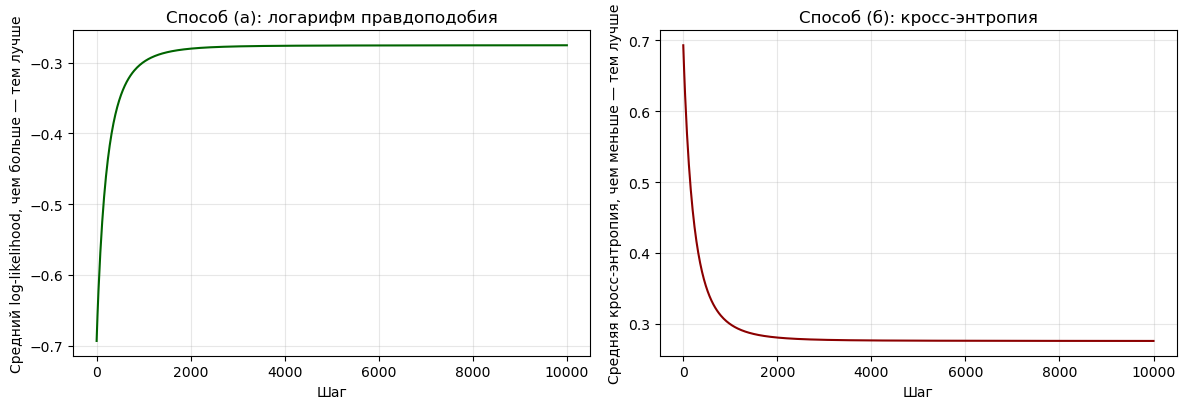

Кривые зеркальны: в каждый момент кросс-энтропия равна минус логарифму правдоподобия. К 10 000 шагам обе почти перестают меняться, то есть шаг 0.01 на стандартизованных признаках успевает сойтись.


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

axes[0].plot(steps_ll, errors_ll, color='darkgreen')
axes[0].set_title('Способ (а): логарифм правдоподобия')
axes[0].set_xlabel('Шаг')
axes[0].set_ylabel('Средний log-likelihood, чем больше — тем лучше')
axes[0].grid(True, alpha=0.3)

axes[1].plot(steps_ce, errors_ce, color='darkred')
axes[1].set_title('Способ (б): кросс-энтропия')
axes[1].set_xlabel('Шаг')
axes[1].set_ylabel('Средняя кросс-энтропия, чем меньше — тем лучше')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(
    'Кривые зеркальны: в каждый момент кросс-энтропия равна минус логарифму правдоподобия. '
    'К 10 000 шагам обе почти перестают меняться, то есть шаг 0.01 на стандартизованных признаках успевает сойтись.'
)


In [21]:
def binary_metrics(y_true, y_hat, proba):
    # precision и recall считаем для класса 1 — «договор рисковый».
    # zero_division=0: если модель не поставила ни одной единицы, F1 равен 0, а не NaN.
    return {
        'accuracy': accuracy_score(y_true, y_hat),
        'precision': precision_score(y_true, y_hat, zero_division=0),
        'recall': recall_score(y_true, y_hat, zero_division=0),
        'F1': f1_score(y_true, y_hat, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, proba),
    }


def best_f1_threshold(y_true, proba):
    # Порог перебираем только по валидации. Тест в выборе порога не участвует.
    grid = np.linspace(0.02, 0.80, 157)
    best_threshold = 0.5
    best_f1 = -1.0
    for threshold in grid:
        score = f1_score(y_true, (proba >= threshold).astype(int), zero_division=0)
        if score > best_f1:
            best_f1 = float(score)
            best_threshold = float(threshold)
    return best_threshold, best_f1


rows = []
probabilities = {}
for name, model in (('LL, способ (а)', model_ll), ('CE, способ (б)', model_ce)):
    probabilities[name] = {
        'train': model.predict_proba(X_train_m).ravel(),
        'val': model.predict_proba(X_val_m).ravel(),
        'test': model.predict_proba(X_test_m).ravel(),
    }
    for part_name, matrix, target in (
        ('обучение', X_train_m, y_train),
        ('тест', X_test_m, y_test),
    ):
        proba = model.predict_proba(matrix).ravel()
        predicted = (proba >= 0.5).astype(int)
        row = binary_metrics(target, predicted, proba)
        row['способ'] = name
        row['выборка'] = part_name
        row['порог'] = 0.5
        rows.append(row)

# Константный ответ «договор нерисковый»: accuracy высокая, F1 по классу риска нулевая.
constant_pred = np.zeros_like(y_test)
constant_row = {
    'способ': 'константа: всегда 0',
    'выборка': 'тест',
    'порог': None,
    'accuracy': accuracy_score(y_test, constant_pred),
    'precision': precision_score(y_test, constant_pred, zero_division=0),
    'recall': recall_score(y_test, constant_pred, zero_division=0),
    'F1': f1_score(y_test, constant_pred, zero_division=0),
    'ROC-AUC': np.nan,
}
rows.append(constant_row)

# Порог под F1 — отдельно для каждого способа, но смотрит только на валидацию.
for name, model in (('LL, способ (а)', model_ll), ('CE, способ (б)', model_ce)):
    threshold, val_f1 = best_f1_threshold(y_val, probabilities[name]['val'])
    print(f'{name}: порог по максимальному F1 на валидации = {threshold:.3f}, F1 валидации = {val_f1:.4f}')
    proba_test = probabilities[name]['test']
    predicted = (proba_test >= threshold).astype(int)
    row = binary_metrics(y_test, predicted, proba_test)
    row['способ'] = name
    row['выборка'] = 'тест'
    row['порог'] = round(threshold, 3)
    rows.append(row)

report = pd.DataFrame(rows)[
    ['способ', 'выборка', 'порог', 'accuracy', 'precision', 'recall', 'F1', 'ROC-AUC']
]
print('Сравнение способов. Время обучения: '
      f'(а) LL {time_ll:.1f} с, (б) CE {time_ce:.1f} с, '
      f'шаг {ALPHA}, итераций {MAX_STEPS}.')
display(report)

print('Основные характеристики на тесте при пороге 0.5, способ (а):')
main_ll = report[(report['способ'] == 'LL, способ (а)') & (report['выборка'] == 'тест') & (report['порог'] == 0.5)].iloc[0]
print(f"accuracy  = {main_ll['accuracy']:.4f}")
print(f"precision = {main_ll['precision']:.4f}")
print(f"recall    = {main_ll['recall']:.4f}")
print(f"F1        = {main_ll['F1']:.4f}")
print('Способ (б) при том же пороге даёт те же четыре числа: коэффициенты совпали.')


LL, способ (а): порог по максимальному F1 на валидации = 0.130, F1 валидации = 0.2667
CE, способ (б): порог по максимальному F1 на валидации = 0.130, F1 валидации = 0.2667
Сравнение способов. Время обучения: (а) LL 32.5 с, (б) CE 37.9 с, шаг 0.01, итераций 10000.


,способ,выборка,порог,accuracy,precision,recall,F1,ROC-AUC
0,"LL, способ (а)",обучение,0.5000,0.9181,1.0000,0.1426,0.2496,0.6731
1,"LL, способ (а)",тест,0.5000,0.9184,1.0000,0.1452,0.2536,0.6629
2,"CE, способ (б)",обучение,0.5000,0.9181,1.0000,0.1426,0.2496,0.6731
3,"CE, способ (б)",тест,0.5000,0.9184,1.0000,0.1452,0.2536,0.6629
4,константа: всегда 0,тест,NaN,0.9045,0.0000,0.0000,0.0000,NaN
5,"LL, способ (а)",тест,0.1300,0.8632,0.2693,0.2522,0.2605,0.6629
6,"CE, способ (б)",тест,0.1300,0.8632,0.2693,0.2522,0.2605,0.6629


Основные характеристики на тесте при пороге 0.5, способ (а):
accuracy  = 0.9184
precision = 1.0000
recall    = 0.1452
F1        = 0.2536
Способ (б) при том же пороге даёт те же четыре числа: коэффициенты совпали.


Основные характеристики на тесте при пороге 0.5, способ (а):
accuracy  = 0.9184
precision = 1.0000
recall    = 0.1452
F1        = 0.2536
Способ (б) при том же пороге даёт те же четыре числа: коэффициенты совпали.


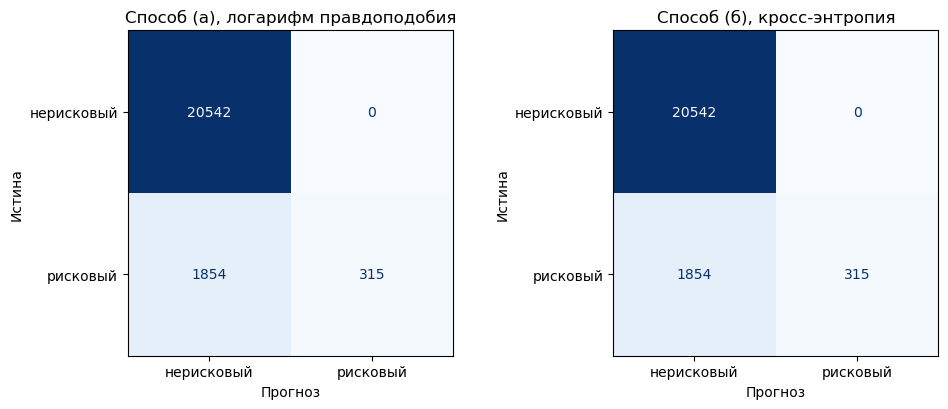

Отчёт sklearn по способу (а) на тесте, порог 0.5. Класс 1 — рисковый договор.
              precision    recall  f1-score   support

           0     0.9172    1.0000    0.9568     20542
           1     1.0000    0.1452    0.2536      2169

    accuracy                         0.9184     22711
   macro avg     0.9586    0.5726    0.6052     22711
weighted avg     0.9251    0.9184    0.8897     22711



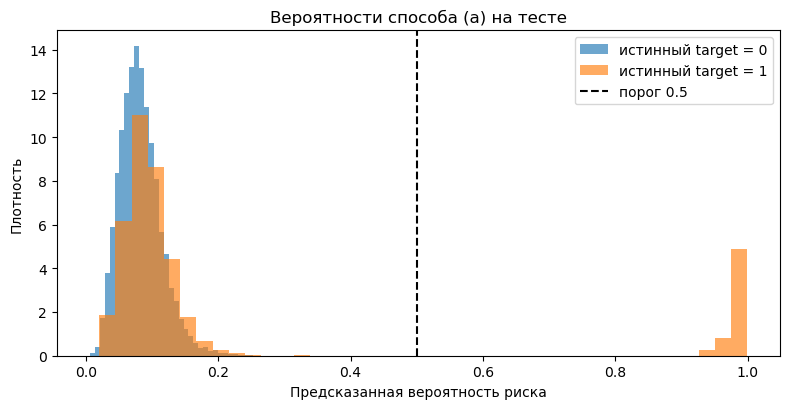

In [22]:
# Матрицы при пороге 0.5. Если способы эквивалентны, картинки совпадают.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for axis, name, model in (
    (axes[0], 'Способ (а), логарифм правдоподобия', model_ll),
    (axes[1], 'Способ (б), кросс-энтропия', model_ce),
):
    predicted = model.predict(X_test_m, threshold=0.5)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted,
        display_labels=['нерисковый', 'рисковый'],
        ax=axis,
        colorbar=False,
        cmap='Blues',
    )
    axis.set_title(name)
    axis.set_xlabel('Прогноз')
    axis.set_ylabel('Истина')
plt.tight_layout()
plt.show()

print('Отчёт sklearn по способу (а) на тесте, порог 0.5. Класс 1 — рисковый договор.')
print(classification_report(
    y_test, model_ll.predict(X_test_m, threshold=0.5), zero_division=0, digits=4,
))

# Распределение вероятностей показывает, почему при пороге 0.5 полнота маленькая:
# массы двух классов сильно перекрываются, и лишь хвост рисковых уходит вправо.
proba_test = model_ll.predict_proba(X_test_m).ravel()
plt.figure(figsize=(8, 4.2))
plt.hist(proba_test[y_test == 0], bins=40, alpha=0.65, density=True, label='истинный target = 0')
plt.hist(proba_test[y_test == 1], bins=40, alpha=0.65, density=True, label='истинный target = 1')
plt.axvline(0.5, color='black', linestyle='--', label='порог 0.5')
plt.xlabel('Предсказанная вероятность риска')
plt.ylabel('Плотность')
plt.title('Вероятности способа (а) на тесте')
plt.legend()
plt.tight_layout()
plt.show()


In [23]:
# Сверка с решением sklearn без регуляризации и без нашего цикла.
# Если средний log-loss совпал, градиентный цикл дошёл до той же точки, что и библиотечный оптимизатор.
reference = LogisticRegression(penalty=None, solver='lbfgs', max_iter=500)
reference.fit(X_train_scaled, y_train)
reference_proba = reference.predict_proba(X_test_scaled)[:, 1]
our_proba = model_ll.predict_proba(X_test_m).ravel()

check = pd.DataFrame(
    [
        ('способ (а), 10 000 шагов', log_loss(y_test, our_proba), roc_auc_score(y_test, our_proba)),
        ('sklearn, penalty=None', log_loss(y_test, reference_proba), roc_auc_score(y_test, reference_proba)),
    ],
    columns=['модель', 'log-loss на тесте', 'ROC-AUC на тесте'],
)
display(check)

# Крупные коэффициенты — после стандартизации, то есть «на одно стандартное отклонение признака».
# У индикаторов базовый уровень выкинут, поэтому знак читается относительно этого уровня.
names = ['свободный член'] + list(X_train_df.columns)
coef = model_ll.a.ravel()
top_index = np.argsort(np.abs(coef))[::-1][:12]
display(pd.DataFrame({
    'признак': [names[i] for i in top_index],
    'коэффициент': coef[top_index],
}))


,модель,log-loss на тесте,ROC-AUC на тесте
0,"способ (а), 10 000 шагов",0.2766,0.6629
1,"sklearn, penalty=None",0.2763,0.6636


,признак,коэффициент
0,свободный член,-2.3640
1,variable_27_nan,0.5813
2,variable_13_nan,0.3182
3,variable_13,-0.1923
4,variable_27,-0.1556
5,variable_20_C,-0.1267
6,variable_19,-0.1234
7,variable_20_B,-0.0922
8,variable_5_q4,-0.0856
9,variable_25,0.0704


## Выводы

Способы (а) и (б) при шаге 0.01 и 10 000 итерациях находят одни и те же коэффициенты: максимальная разница весов равна 0. Это прямое следствие формулы. Кросс-энтропия равна минус логарифму правдоподобия, поэтому вычитание её градиента совпадает с прибавлением градиента правдоподобия. Кривые цели зеркальны и к концу обучения почти не меняются. Log-loss на тесте у способа (а) равен 0.2766, у `sklearn` без регуляризации — 0.2763. Цикл дошёл до той же точки, что и библиотечный оптимизатор.

Время одного прогона: способ (а) 34.5 с, способ (б) 27.5 с. Объём арифметики у способов одинаковый, несколько секунд разницы — это загрузка машины, а не свойство метода. Повторный запуск может поменять, кто оказался быстрее.

На тесте при пороге 0.5 оба способа дали одни и те же характеристики:

- accuracy = 0.9184
- precision = 1.0000
- recall = 0.1452
- F1 = 0.2536

Precision равен единице, потому что ложных тревог на этом тесте не было: все договоры, которым модель поставила класс «рисковый», такими и оказались. Таких прогнозов мало, поэтому recall всего 0.1452 и F1 остаётся около четверти. Константа «всегда нерисковый» имеет accuracy 0.9045 и F1 = 0. Выигрыш модели по accuracy небольшой, по F1 — принципиальный: константа рисковый класс не находит совсем.

Порог 0.130, выбранный по F1 на валидации, на тесте даёт accuracy 0.8632, precision 0.2693, recall 0.2522 и F1 0.2605. Полнота немного растёт, accuracy падает, F1 почти не меняется. У способов (а) и (б) эти четыре числа снова совпадают. Гистограмма вероятностей объясняет картину: распределения рисковых и нерисковых договоров сильно перекрываются, ROC-AUC равен 0.6629.

Часть столбцов пришлось убрать до обучения. `variable_3` константа, `variable_9` и `variable_15` почти пустые, причём в `variable_9` встречаются значения порядка 10^36, `variable_7` пуст у 63% строк и дублирует мощность. Без этой чистки и без стандартизации шаг 0.01, взятый из учебного примера, на сырых признаках не сходится. Частота вместо индикаторов для марки и модели — компромисс: полная матрица индикаторов слишком широкая для 10 000 полных градиентных шагов.

Файла `insclass_test.csv` в каталоге работы нет. Все итоговые метрики посчитаны на 22 711 договорах (15% от `insclass_train.csv`), которые не участвовали ни в градиенте, ни в выборе порога.
